In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("covid_data.csv")

df.head()

,Date,Country,Confirmed,Recovered,Deaths
0,22-01-2020,Afghanistan,0,0,0
1,23-01-2020,Afghanistan,0,0,0
2,24-01-2020,Afghanistan,0,0,0
3,25-01-2020,Afghanistan,0,0,0
4,26-01-2020,Afghanistan,0,0,0


In [7]:
print("Total Records:", len(df))

print("Total Countries:", df["Country"].nunique())

print("Total Columns:", len(df.columns))

df.info()

Total Records: 161568
Total Countries: 198
Total Columns: 5
<class 'pandas.DataFrame'>
RangeIndex: 161568 entries, 0 to 161567
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   Date       161568 non-null  str  
 1   Country    161568 non-null  str  
 2   Confirmed  161568 non-null  int64
 3   Recovered  161568 non-null  int64
 4   Deaths     161568 non-null  int64
dtypes: int64(3), str(2)
memory usage: 9.0 MB


In [8]:
print(df.columns)

Index(['Date', 'Country', 'Confirmed', 'Recovered', 'Deaths'], dtype='str')


In [9]:
df.describe()

,Confirmed,Recovered,Deaths
count,1.615680e+05,1.615680e+05,161568.000000
mean,7.361569e+05,1.453967e+05,13999.436089
std,3.578884e+06,9.748275e+05,59113.581271
min,0.000000e+00,0.000000e+00,0.000000
25%,1.220000e+03,0.000000e+00,17.000000
50%,2.369200e+04,1.260000e+02,365.000000
75%,2.558420e+05,1.797225e+04,4509.000000
max,8.062512e+07,3.097475e+07,988609.000000


In [10]:
df = df[[
    "Date",
    "Country",
    "Confirmed",
    "Recovered",
    "Deaths"
]]

df.head()

,Date,Country,Confirmed,Recovered,Deaths
0,22-01-2020,Afghanistan,0,0,0
1,23-01-2020,Afghanistan,0,0,0
2,24-01-2020,Afghanistan,0,0,0
3,25-01-2020,Afghanistan,0,0,0
4,26-01-2020,Afghanistan,0,0,0


In [11]:
df.isnull().sum()

Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64

In [12]:
df = df.drop_duplicates()

print("Duplicate records removed.")
print("Total Records:", len(df))

Duplicate records removed.
Total Records: 161568


In [13]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

df = df.sort_values("Date")

df.head()

,Date,Country,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,0,0,0
44880,2020-01-22,El Salvador,0,0,0
44064,2020-01-22,Egypt,0,0,0
43248,2020-01-22,Ecuador,0,0,0
147696,2020-01-22,Tunisia,0,0,0


In [14]:
df = df.dropna(subset=["Date", "Country"])

df[["Confirmed", "Recovered", "Deaths"]] = (
    df[["Confirmed", "Recovered", "Deaths"]].fillna(0)
)

print("Data cleaning completed.")

df.isnull().sum()

Data cleaning completed.


Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64

In [15]:
world = df.groupby("Date")[
    ["Confirmed", "Recovered", "Deaths"]
].sum().reset_index()

world.tail()

,Date,Confirmed,Recovered,Deaths
811,2022-04-12,500880363,0,6185040
812,2022-04-13,501920234,0,6189593
813,2022-04-14,502892186,0,6193401
814,2022-04-15,503606396,0,6195647
815,2022-04-16,504155459,0,6197159


In [16]:
print("COVID-19 GLOBAL STATISTICS")
print("--------------------------")

print("Total Confirmed Cases:", world["Confirmed"].iloc[-1])

print("Total Recovered Cases:", world["Recovered"].iloc[-1])

print("Total Deaths:", world["Deaths"].iloc[-1])

COVID-19 GLOBAL STATISTICS
--------------------------
Total Confirmed Cases: 504155459
Total Recovered Cases: 0
Total Deaths: 6197159


In [17]:
world["New Cases"] = world["Confirmed"].diff()

world["New Cases"] = world["New Cases"].fillna(0)

world.head()

,Date,Confirmed,Recovered,Deaths,New Cases
0,2020-01-22,557,30,17,0.0
1,2020-01-23,657,32,18,100.0
2,2020-01-24,944,39,26,287.0
3,2020-01-25,1437,42,42,493.0
4,2020-01-26,2120,56,56,683.0


In [18]:
world["New Deaths"] = world["Deaths"].diff()

world["New Deaths"] = world["New Deaths"].fillna(0)

world.head()

,Date,Confirmed,Recovered,Deaths,New Cases,New Deaths
0,2020-01-22,557,30,17,0.0,0.0
1,2020-01-23,657,32,18,100.0,1.0
2,2020-01-24,944,39,26,287.0,8.0
3,2020-01-25,1437,42,42,493.0,16.0
4,2020-01-26,2120,56,56,683.0,14.0


In [19]:
world["Cases_MA_7"] = world["New Cases"].rolling(7).mean()

world["Deaths_MA_7"] = world["New Deaths"].rolling(7).mean()

world.tail()

,Date,Confirmed,Recovered,Deaths,New Cases,New Deaths,Cases_MA_7,Deaths_MA_7
811,2022-04-12,500880363,0,6185040,1036861.0,3303.0,1.030187e+06,3685.285714
812,2022-04-13,501920234,0,6189593,1039871.0,4553.0,9.710847e+05,3250.428571
813,2022-04-14,502892186,0,6193401,971952.0,3808.0,9.362524e+05,3213.428571
814,2022-04-15,503606396,0,6195647,714210.0,2246.0,8.678173e+05,2947.857143
815,2022-04-16,504155459,0,6197159,549063.0,1512.0,8.364947e+05,2835.714286


In [20]:
world["Death Rate"] = (
    world["Deaths"] / world["Confirmed"]
) * 100

world["Death Rate"] = world["Death Rate"].replace(
    [np.inf, -np.inf], np.nan
)

print("Average Death Rate:",
      round(world["Death Rate"].mean(), 2), "%")

Average Death Rate: 2.87 %


In [21]:
countries = ["India", "US", "Brazil"]

country_data = df[df["Country"].isin(countries)]

country_data.head()

,Date,Country,Confirmed,Recovered,Deaths
149328,2020-01-22,US,1,0,0
19584,2020-01-22,Brazil,0,0,0
65280,2020-01-22,India,0,0,0
65281,2020-01-23,India,0,0,0
149329,2020-01-23,US,1,0,0


In [22]:
latest_data = (
    country_data.sort_values("Date")
    .groupby("Country")
    .tail(1)
)

print(latest_data[[
    "Country",
    "Confirmed",
    "Recovered",
    "Deaths"
]])

       Country  Confirmed  Recovered  Deaths
20399   Brazil   30250077          0  662185
66095    India   43042097          0  521751
150143      US   80625120          0  988609


In [23]:
latest_all = (
    df.sort_values("Date")
    .groupby("Country")
    .tail(1)
)

highest_country = latest_all.loc[
    latest_all["Confirmed"].idxmax()
]

print("Country with Highest Cases:",
      highest_country["Country"])

print("Total Cases:",
      highest_country["Confirmed"])

Country with Highest Cases: US
Total Cases: 80625120


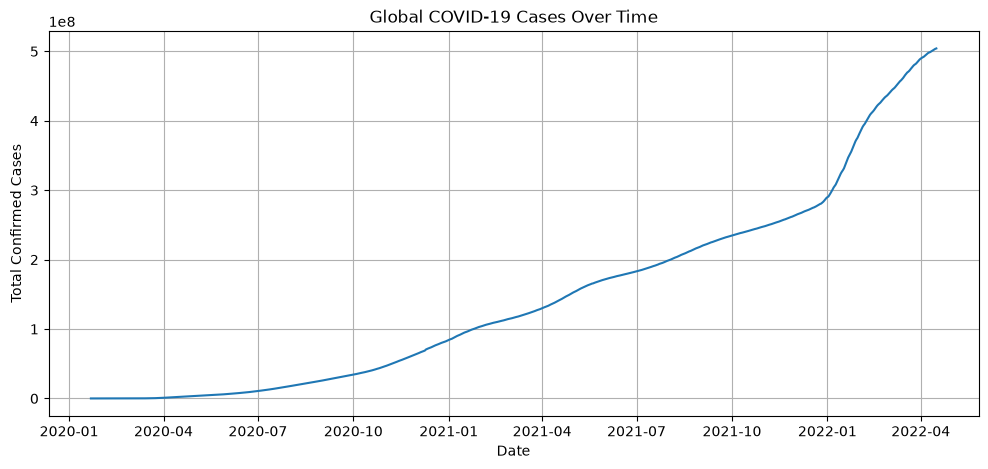

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(world["Date"], world["Confirmed"])

plt.title("Global COVID-19 Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Total Confirmed Cases")

plt.grid()
plt.show()

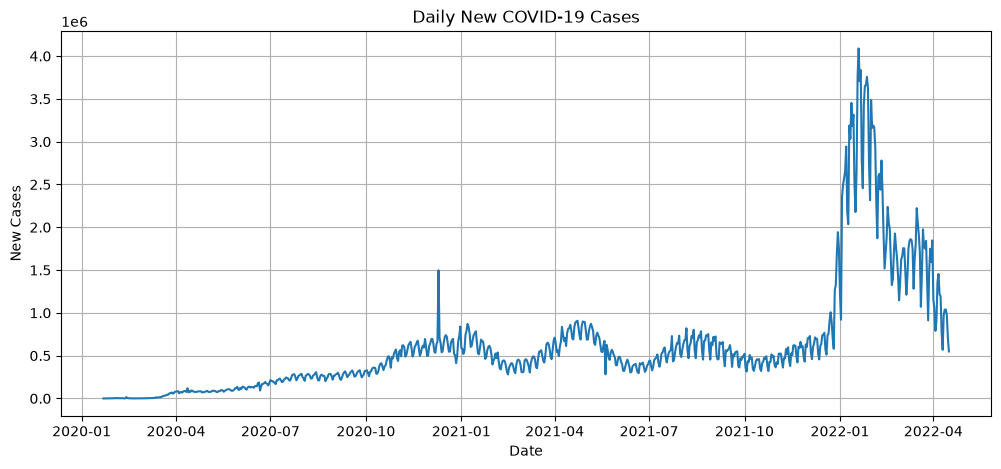

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(world["Date"], world["New Cases"])

plt.title("Daily New COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("New Cases")

plt.grid()
plt.show()

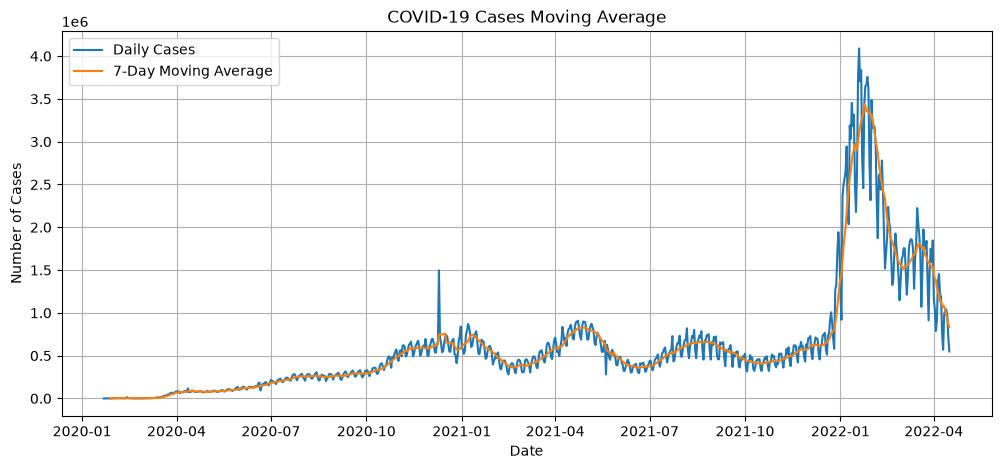

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(world["Date"], world["New Cases"],
         label="Daily Cases")

plt.plot(world["Date"], world["Cases_MA_7"],
         label="7-Day Moving Average")

plt.title("COVID-19 Cases Moving Average")
plt.xlabel("Date")
plt.ylabel("Number of Cases")

plt.legend()
plt.grid()
plt.show()

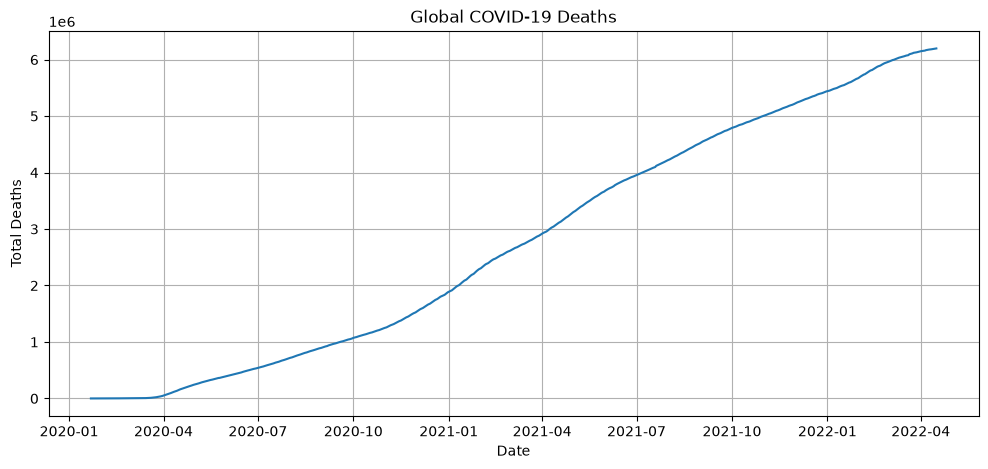

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(world["Date"], world["Deaths"])

plt.title("Global COVID-19 Deaths")
plt.xlabel("Date")
plt.ylabel("Total Deaths")

plt.grid()
plt.show()

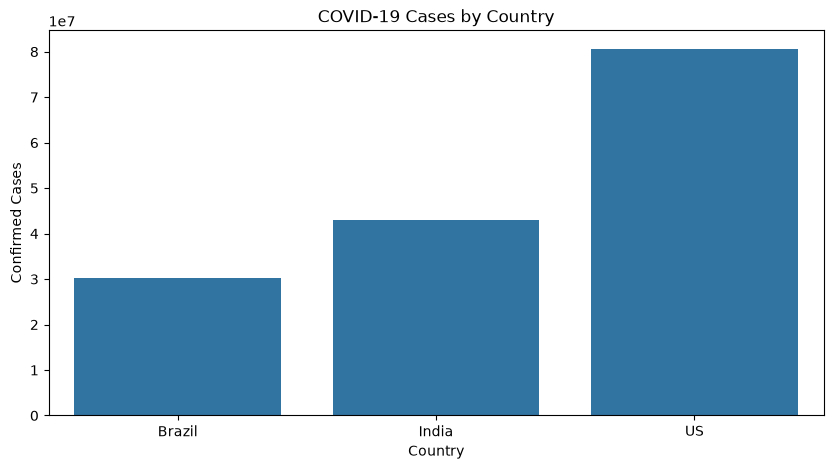

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=latest_data,
    x="Country",
    y="Confirmed"
)

plt.title("COVID-19 Cases by Country")
plt.xlabel("Country")
plt.ylabel("Confirmed Cases")

plt.show()

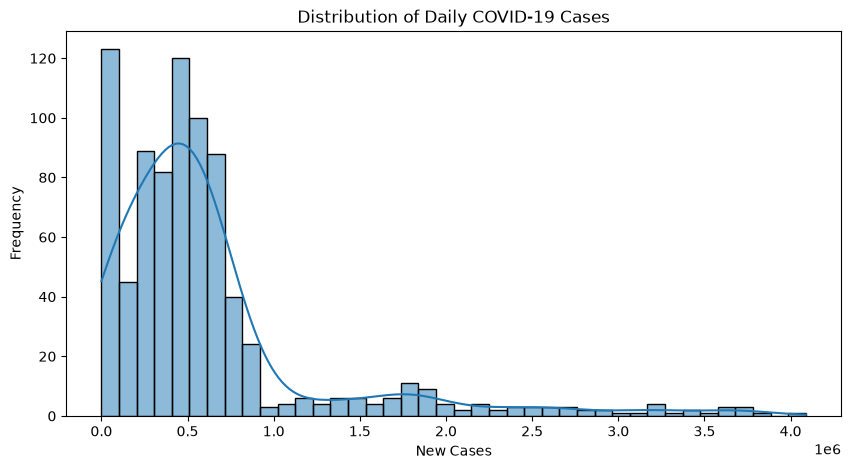

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    world["New Cases"].dropna(),
    bins=40,
    kde=True
)

plt.title("Distribution of Daily COVID-19 Cases")
plt.xlabel("New Cases")
plt.ylabel("Frequency")

plt.show()

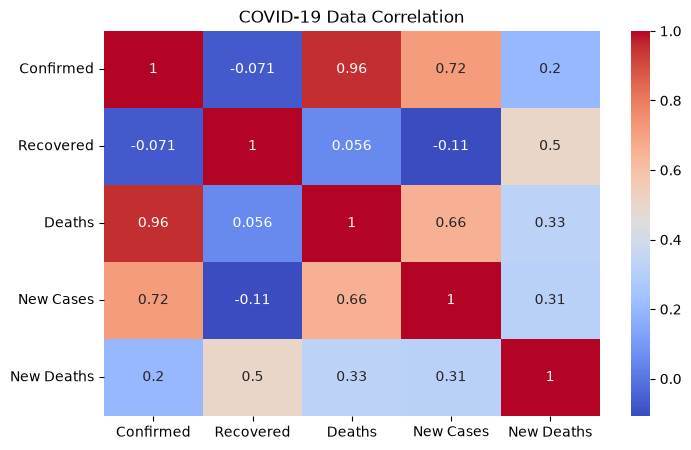

In [30]:
plt.figure(figsize=(8, 5))

correlation = world[
    ["Confirmed", "Recovered", "Deaths",
     "New Cases", "New Deaths"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("COVID-19 Data Correlation")

plt.show()

In [31]:
print("COVID-19 DATA ANALYSIS")
print("======================")

print("Total Countries:", df["Country"].nunique())

print("Total Confirmed Cases:",
      world["Confirmed"].iloc[-1])

print("Total Recovered:",
      world["Recovered"].iloc[-1])

print("Total Deaths:",
      world["Deaths"].iloc[-1])

print("Highest Daily Cases:",
      world["New Cases"].max())

print("Highest Daily Deaths:",
      world["New Deaths"].max())

COVID-19 DATA ANALYSIS
Total Countries: 198
Total Confirmed Cases: 504155459
Total Recovered: 0
Total Deaths: 6197159
Highest Daily Cases: 4089026.0
Highest Daily Deaths: 20726.0


In [32]:
world.to_csv("COVID19_Analysis_Result.csv", index=False)

print("COVID-19 Analysis Completed Successfully!")

COVID-19 Analysis Completed Successfully!
